In [8]:
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy.stats import linregress
from scipy.signal import find_peaks
import re

In [2]:
def wavenumber(wavelength):
    """
    Calculates k from lambda
    Args:
        wavelength (float): the wavelength of light in nm
    Returns:
        k (float): wavenumber of light in per m
    """
    wavelength = wavelength * (1e-9) # converts to metres
    k = (2*math.pi)/wavelength # calculates k
    return k

def fourier_transform(x,y):
    """
    Does a fourier transform on a graph to find the constituent frequencies
    Args:
        x (np.array): linearly spaces x values
        y (np.array): the array of amplitude
    Returns:
        fft_freq (np.array): the frequencies found
        mag (np.array): the intensities of frequencies
    """
    fft_val = np.fft.fftshift(np.fft.fft(y))
    fft_freq = np.fft.fftshift(np.fft.fftfreq(len(x), x[1]-x[0]))
    mag = (fft_val)
    return fft_freq, mag

def read_interferogram_base(image, pixel_size, axis):
    """
    Reads an interferogram via summation, so not valid for a measurement with phase shift
    Args:
        image (str): The string of the image name
        pixel_size (float): The size of pixels in metres
        axis (int): The axis being summed across (0 for vertical lines, 1 for horizontal lines)
    Returns:
        x (np.array): An array of distances across the camera
        y (np.array): A normalised sum of intensities
    """
    img = mpimg.imread(image) # reads the image
    summation = np.sum(img, axis) # sums along specified axis

    x = np.linspace(0, len(summation)*pixel_size, len(summation)) # sets up linear spacing scaled for right length and pixel size
    y = summation/np.max(summation) # normalises the magnitude
    return x, y

def do_everything(image, pixel_size, axis, wavelength):
    """
    Reads an interferogram and performs immediate FFT on it
    Args:
        image (str): The string of the image name
        pixel_size (float): The size of pixels in metres
        axis (int): The axis being summed across (0 for vertical lines, 1 for horizontal lines)
        wavelength (float): the wavelength of light in nm
    Returns:
        degrees (np.array): the degrees of theta
        mag (np.array): magnitudes of frequencies from fft
    """
    x,y = read_interferogram_base(image, pixel_size, axis)
    freq, mag = fourier_transform(x,y)
    degrees = np.degrees(freq*2*np.pi/wavenumber(wavelength))
    mid = len(degrees) //2
    degrees = degrees[mid:]
    mag = mag[mid:]
    return degrees, mag

def simple_moving_average(data, window_size):
    weights = np.ones(window_size) / window_size
    return np.convolve(data, weights, mode='valid')

Wider lines = smaller theta

C:\Users\kwb26754\test_env\.venv\Lib\site-packages\matplotlib\cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
C:\Users\kwb26754\test_env\.venv\Lib\site-packages\matplotlib\cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)
C:\Users\kwb26754\test_env\.venv\Lib\site-packages\matplotlib\cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
C:\Users\kwb26754\test_env\.venv\Lib\site-packages\matplotlib\cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)
C:\Users\kwb26754\test_env\.venv\Lib\site-packages\matplotlib\cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
C:\Users\kwb26754\test_env\.venv\Lib\site-packages\matplotlib\cbook.py:1407: ComplexWarnin

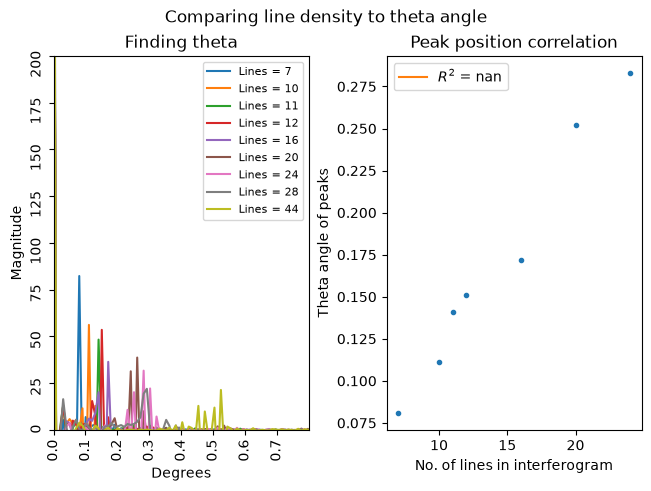

In [3]:
lines_count = [7,11,12,16,28,20,44,24,10]
lines_count = sorted(lines_count,key=None,reverse=False)
wavelength = 635 # in nanometres
pixel_size = 3.75e-6 # from camera specs
axis = 1 # horizontal lines
x_limit = 8e-1 # arbitrary for good graphing
peaks = []

# set up initial plots
fig, ax = plt.subplots(1,2, layout = "constrained")
fig.suptitle('Comparing line density to theta angle')

for i in range(len(lines_count)):
    image_code = ('interferograms/test_im_'+str(lines_count[i])+'_lines.bmp') # creates correct string for reading
    x,y = do_everything(image_code, pixel_size, axis, wavelength) # reads image and does fft, converting into degrees
    x1 = x[5:] # removes initial angle values so as to make rough peakfinding algorith
    y1 = y[5:]
    check = np.where(y1 > 25)[0]
    peak = round(float(np.average(x1[check])), 3)
    # as lines_count increases, there is peak broadening
    # average x value for these peaks is a rough peak finding algorithm
    ax[0].plot(x,y, label = f'Lines = {lines_count[i]}')
    peaks.append(peak)

ax[0].set_xlim(0,x_limit)
ax[0].set_ylim(0,200)
ax[0].set_xlabel('Degrees')
ax[0].set_ylabel('Magnitude')
ax[0].legend(fontsize = 8)
ax[0].set_title('Finding theta')
ax[0].set_xticks(np.arange(0,x_limit,0.1))
ax[0].tick_params(labelrotation=90)

ax[1].plot(lines_count, peaks, '.')
slope, intercept, r_value, p_value, std_err = linregress(lines_count, peaks)
ax[1].plot(np.unique(lines_count), np.poly1d(np.polyfit(lines_count, peaks, 1))(np.unique(lines_count)), label = f'$R^2$ = {round(r_value**2,3)}') # best fit line
ax[1].legend()
ax[1].set_xlabel('No. of lines in interferogram')
ax[1].set_ylabel('Theta angle of peaks')
ax[1].set_title('Peak position correlation')

plt.savefig("peak_position_data.png")
plt.show()

C:\Users\kwb26754\test_env\.venv\Lib\site-packages\matplotlib\cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
C:\Users\kwb26754\test_env\.venv\Lib\site-packages\matplotlib\cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)
C:\Users\kwb26754\test_env\.venv\Lib\site-packages\matplotlib\cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
C:\Users\kwb26754\test_env\.venv\Lib\site-packages\matplotlib\cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)
C:\Users\kwb26754\test_env\.venv\Lib\site-packages\matplotlib\cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
C:\Users\kwb26754\test_env\.venv\Lib\site-packages\matplotlib\cbook.py:1407: ComplexWarnin

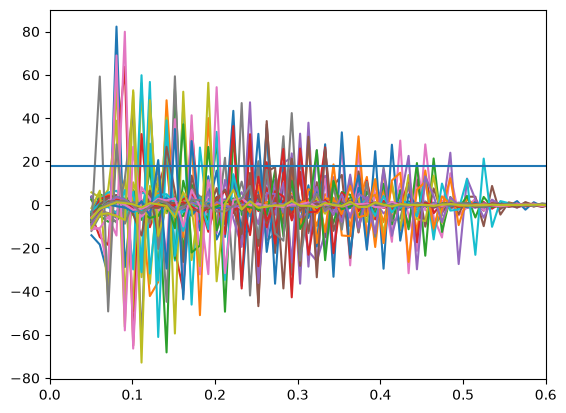

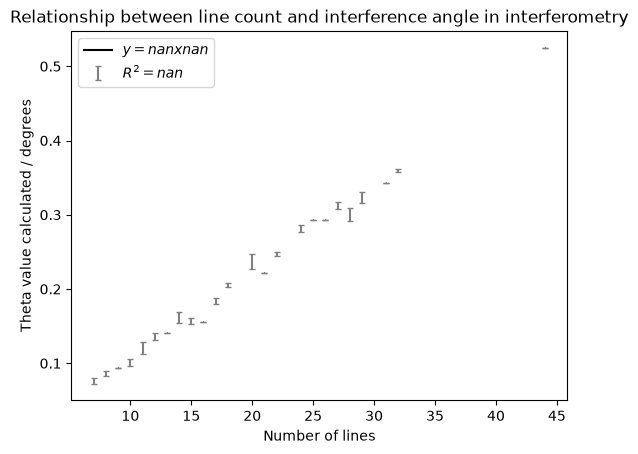

The p-value of this data is nan with a count of 69 data points
There are 32 unique data points


In [4]:
lines_count = [7,11,12,16,28,20,'42a',24,10,14,'24a',34,'12a',9,27,42,32,21,'14a',
               '10a','20a',17,18,23,'42c',30,37,13,'10b','12b',31,39,'30a',36,29,22,
               15,'11a',8,'12c','22a','32a','42b','29a','22b','13a','10c','37a',
               '39a',44,'36a','27a','17a','22c','30b','28a','8a','7a','11b','18a',
              '15a',38,'27b',25,'38a','24b','18b',26,'17b']
wavelength = 635 # in nanometres
pixel_size = 3.75e-6 # from camera specs
axis = 1 # horizontal lines
peaks = [] # form nested list [[number of lines, x position of peak, x position of peak...]...]
lines_list = [] # list of lines
means = [] # list of means of theta values
standard_errors = [] # list of standard errors, 0 if only one data point for given line
mag_limit = 18

for i in range(len(lines_count)):
    image_code = ('interferograms/test_im_'+str(lines_count[i])+'_lines.bmp') # creates correct string for reading
    x,y = do_everything(image_code, pixel_size, axis, wavelength) # reads image and does fft, converting into degrees
    x1 = x[5:] # removes initial angle values so as to make rough peakfinding algorithm
    y1 = y[5:]
    plt.plot(x1,y1)
    check = np.where(y1 > mag_limit)[0] # finds indexes where the y value is bigger than 25 (ie a peak)
    peak = round(float(np.average(x1[check])), 3) # uses these values to get peak positions
    
    # as lines_count increases, there is peak broadening
    # average x value for these peaks is a rough peak finding algorithm

    # below recovers line count information from manual counting

    if type(lines_count[i]) == str:
        # if the position is a string, remove the letters to get the no. of lines
        line = int(re.sub("[qwertyuiopasdfghjklzxcvbnm]",'',lines_count[i]))
    else:
        line = int(lines_count[i])

    # if the line number has already been recorded, it will add the value of theta onto the end of that list
    # if not, it adds a new list
    is_already_listed = False
    if i == 0:
        # initial one will always add, this stops a potential error with reading a nested list that is actually just one empty list
        peaks.append([line,peak])
    else:
        for j in range(len(peaks)):
            if peaks[j][0] == line:
                peaks[j].append(peak)
                is_already_listed = True
        if is_already_listed == False:
            peaks.append([line,peak])
plt.xlim(0,0.6)
plt.hlines(y=mag_limit,xmin=0,xmax=0.6)
plt.show()
for i in range(len(peaks)):
    lines_list.append(peaks[i].pop(0)) # removes and makes list of just the line count
    if len(peaks[i]) > 1:
        means.append(round(float(np.mean(peaks[i])),3))
        standard_errors.append(round(float(np.std(peaks[i])/math.sqrt(len(peaks[i]))),5)) # creates new lists of means and stdev if needed
    else:
        means.append(peaks[i][0])
        standard_errors.append(0) # if not needed ie only one result, just writes into new list

x_axis = np.linspace(min(lines_list), max(lines_list), 1000)
slope, intercept, r_value, p_value, std_err = linregress(lines_list, means) # line of best fit calculation
plt.errorbar(lines_list, means, yerr=standard_errors, fmt = ',', color = 'gray', capsize = 2.5, label = f'$R^2 = {round(r_value**2,4)}$') # plots for error bars
plt.plot(x_axis, [slope * x + intercept for x in x_axis], label = f'$y = {round(slope,4)}x {round(intercept,4)}$', color = 'black') # best fit line

plt.legend()
plt.xlabel('Number of lines')
plt.ylabel('Theta value calculated / degrees')
plt.title('Relationship between line count and interference angle in interferometry')
plt.show()

print(f'The p-value of this data is {p_value} with a count of {len(lines_count)} data points')
print(f'There are {len(peaks)} unique data points')

In [5]:
# further error source from peak finding algorithm needs quantification
# intuitively larger error at lower line count due to nature of peaks

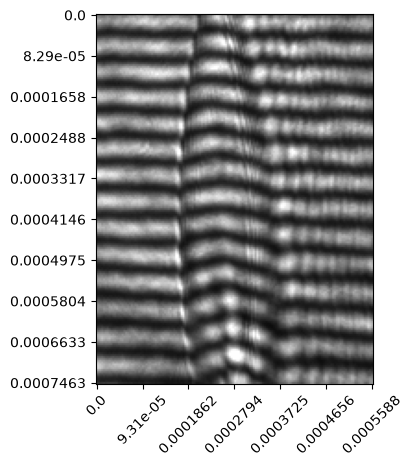

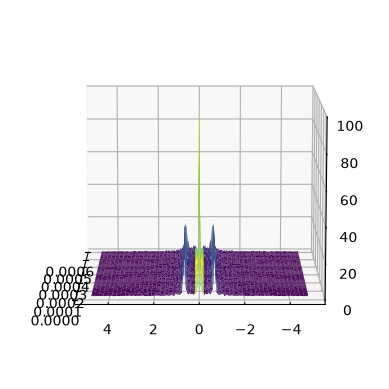

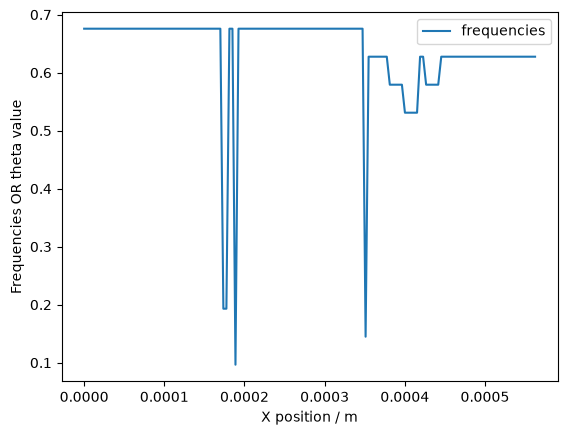

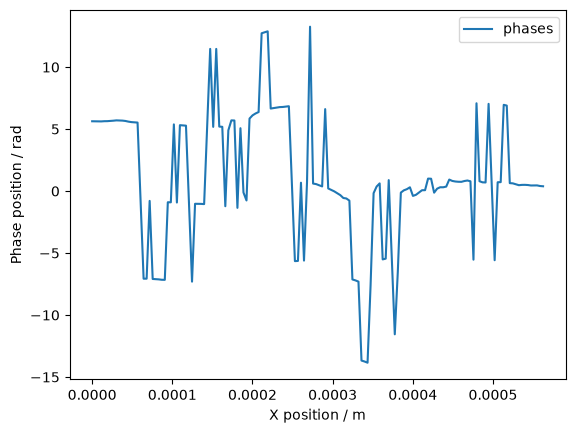

In [5]:
import cv2
pixel_size = 3.75e-6 # from camera specs
wavelength = 635

image = cv2.imread('interferograms/third_interferogram.bmp')

cropped = image[400:600, 300:450]
cv2.imwrite('cropped_image.png',cropped)
ref = image[250:700, 300:350]
cv2.imwrite('reference_image.png',ref)

img=plt.imread('cropped_image.png')
ref = plt.imread('reference_image.png')
plt.imshow(img)
x_ax = np.linspace(0,149,7)
x_ax_spatial = [round(x*pixel_size,7) for x in x_ax]
y_ax = np.linspace(0,199,10)
y_ax_spatial = [round(y*pixel_size,7) for y in y_ax]
plt.yticks(y_ax, y_ax_spatial)
plt.xticks(x_ax,x_ax_spatial,rotation=45)
y = np.linspace(0,len(img)*pixel_size, len(img))
x = np.linspace(0,len(img[0])*pixel_size, len(img[0])) # sets spatial axes correctly

overall_list = []

for i in range(len(img[0])):
    intensity_list = []
    for j in range(len(img)):
        intensity_list.append(img[j][i][0])
    freq,mag = fourier_transform(y,intensity_list)
    overall_list.append(mag)
  
freq = np.degrees(freq*2*np.pi/wavenumber(wavelength))
overall_list = list(map(list, zip(*overall_list)))

x_mesh,freq_mesh = np.meshgrid(x,freq)
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x_mesh, freq_mesh, np.abs(overall_list), cmap = 'viridis',axlim_clip=True)
ax.view_init(elev = 10, azim=180,roll=0)
plt.show()

index_to_be_observed = np.linspace(0,len(overall_list[0])-1,len(overall_list[0]))
frequencies = []
phases = []

for k in range(len(index_to_be_observed)):
    first_index = np.transpose(overall_list)[k]
    mid_point = len(first_index)//2
    first_index_half = first_index[mid_point:]
    freq_half = freq[mid_point:]
    first_index_removed = first_index_half[2:]
    freq_removed = freq_half[2:]
    
    #plt.plot(freq_removed,abs(first_index_removed))
    #plt.show()
    
    index_of_max = int(np.where(first_index_removed == max(first_index_removed))[0][0])
    frequencies.append(freq_removed[index_of_max])
    phases.append(np.unwrap(np.angle(first_index_removed))[index_of_max])
#plt.plot(freq_removed, np.unwrap(np.angle(first_index_removed)))
#plt.show()

plt.plot(x,frequencies,label = 'frequencies')
plt.xlabel('X position / m')
plt.ylabel('Frequencies OR theta value')
plt.legend()
plt.show()

plt.plot(x,phases,label = 'phases')
plt.xlabel('X position / m')
plt.ylabel('Phase position / rad')
plt.legend()
plt.show()

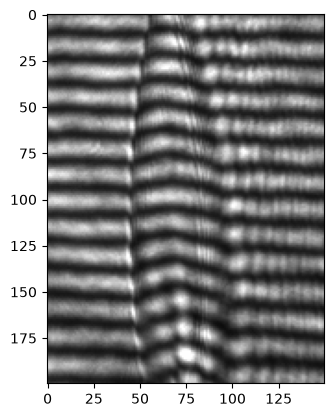

In [107]:
import cv2
pixel_size = 3.75e-6 # from camera specs
wavelength = 635

image = cv2.imread('interferograms/third_interferogram.bmp')

cropped = image[400:600, 300:450]
cv2.imwrite('cropped_image.png',cropped)
ref = image[250:700, 300:350]
cv2.imwrite('reference_image.png',ref)

img=plt.imread('cropped_image.png')
ref = plt.imread('reference_image.png')
plt.imshow(img)
# x_ax = np.linspace(0,149,7)
# x_ax_spatial = [round(x*pixel_size,7) for x in x_ax]
# y_ax = np.linspace(0,199,10)
# y_ax_spatial = [round(y*pixel_size,7) for y in y_ax]
# plt.yticks(y_ax, y_ax_spatial)
# plt.xticks(x_ax,x_ax_spatial,rotation=45)
plt.show()

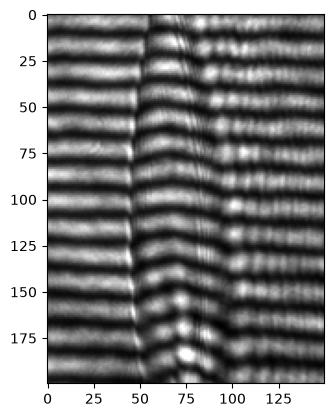

In [31]:
img_condensed = []
for i in range(len(img)):
    img_condensed.append([item[0] for item in img[i]])
plt.imshow(img_condensed,cmap = 'gray')

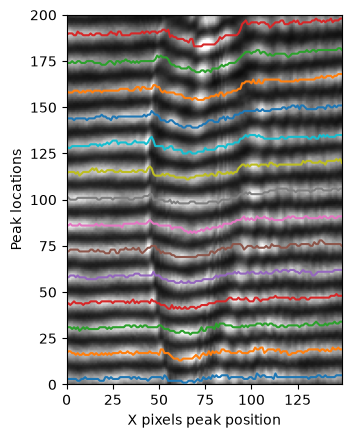

In [32]:
img_condensed_transpose = list(map(list, zip(*img_condensed)))
overall_peaks = []
for i in range(len(img_condensed_transpose)):
    overall_peaks.append([int(x) for x in list(find_peaks(img_condensed_transpose[i],distance=9)[0])])
peaks_transposed = list(map(list, zip(*overall_peaks)))
delta_y_list = [] # takes the form [difference, average of line]
for i in range(len(peaks_transposed)):
    smoothed = simple_moving_average(peaks_transposed[i],1)
    plt.plot(np.linspace(0,len(peaks_transposed[0])-1,len(smoothed)),smoothed)
    line_average = list(smoothed[:35])
    line_average.extend(list(smoothed[115:]))
    delta_y_list.append(float(np.average(line_average) - np.min(smoothed)))
plt.xlabel('X pixels peak position')
plt.xlim(0,len(peaks_transposed[0])-1)
plt.ylim(0,200)
plt.ylabel('Peak locations')
plt.imshow(img)
plt.savefig("mapping_lines.png")
plt.show()

In [6]:
n = 1.3316
thicknesses = [x*(wavelength*1e-9)/(2*np.pi*(n-1)) for x in delta_y_list]
thicknesses

[8.098307051776566e-07,
 1.3758414130975246e-06,
 1.3845492701424458e-06,
 1.4455042694568916e-06,
 1.4280885553670497e-06,
 1.5412906969510262e-06,
 1.9070206928377063e-06,
 1.5456446254734839e-06,
 2.0158689058992206e-06,
 2.1116553333933482e-06,
 2.4948010433698767e-06,
 2.5035089004148013e-06,
 2.512216757459717e-06,
 3.056457822767288e-06]

C:\Users\kwb26754\AppData\Local\Temp\ipykernel_32644\4063343426.py:27: RuntimeWarning: invalid value encountered in divide
  reconstruction = 1.0 - (reconstruction - reconstruction.min()) / (reconstruction.max() - reconstruction.min())


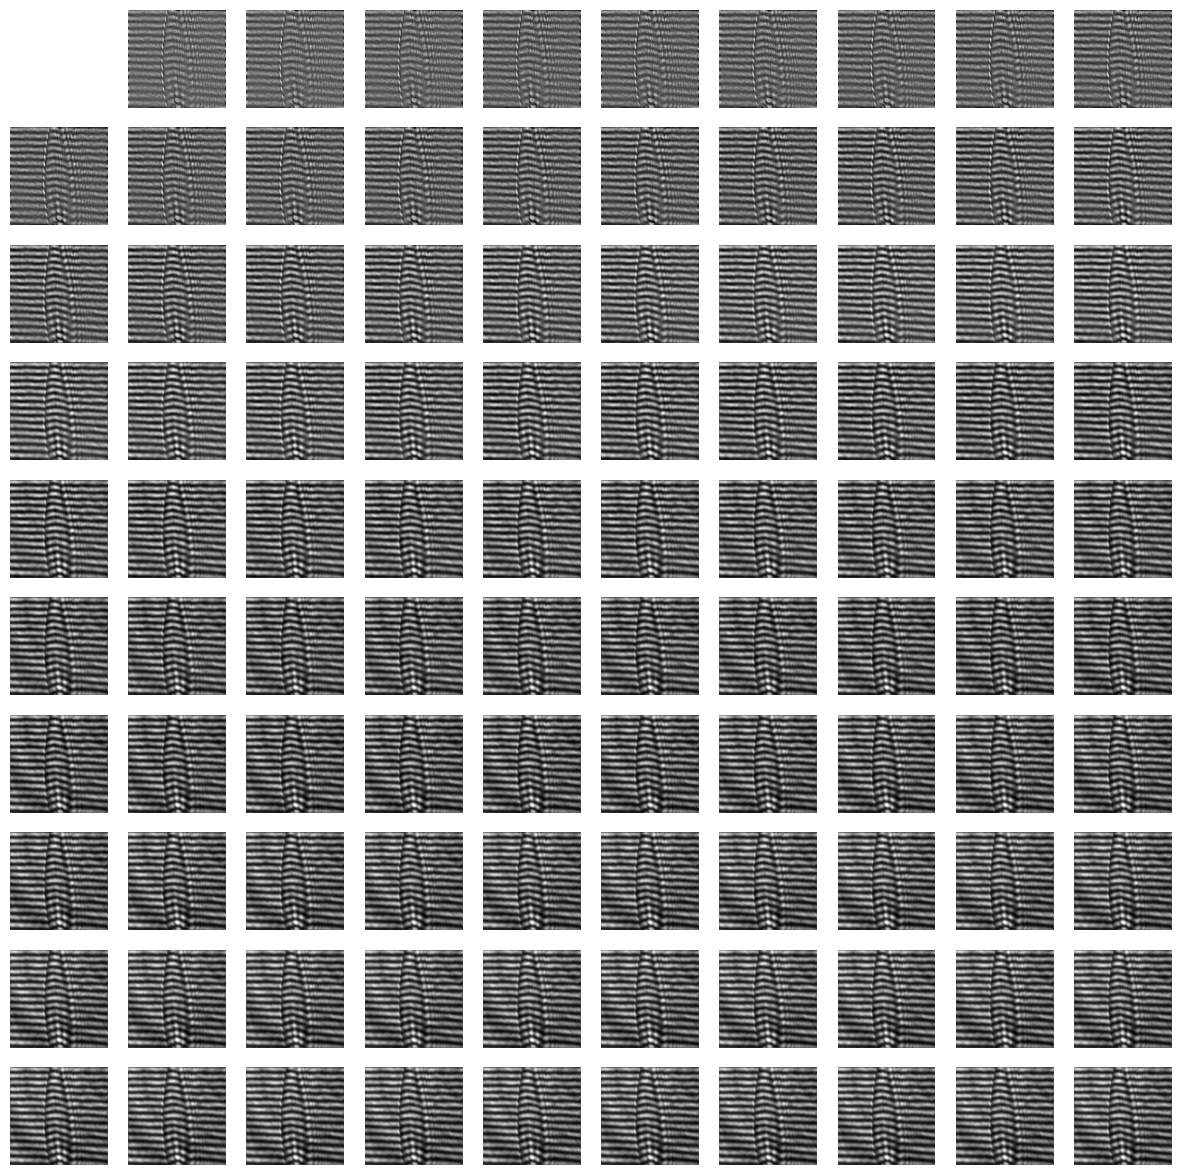

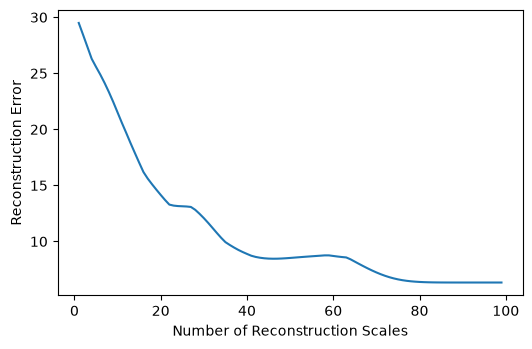

In [56]:
import numpy as np
import pywt
import py_cwt2d
from matplotlib import pylab as plt

# get an image
image_read = cv2.imread('interferograms/third_interferogram.bmp')
grey = cv2.cvtColor(image_read, cv2.COLOR_BGR2GRAY)
image = grey[400:600, 275:475]

image = (image - image.min()) / (image.max() - image.min())
# set up a range of scales in logarithmic spacing between 1 and 256 (image width / 2 seems to work ehre)
ss = np.geomspace(1.0,256.0,100)
# calculate the complex pycwt and the wavelet normalizations
coeffs, wav_norm = py_cwt2d.cwt_2d(image, ss, 'mexh')
# plot an image showing the combinations of all the scales
errors = []
N = 10
fig, axes = plt.subplots(nrows=N, ncols=N, figsize=(15, 15))
for level in range(len(ss)):
    i = level // N
    j = level % N
    plt.sca(axes[i, j])
    plt.axis('off')
    C = 1.0 / (ss[:level] * wav_norm[:level])
    reconstruction = (C * np.real(coeffs[..., :level])).sum(axis=-1)
    reconstruction = 1.0 - (reconstruction - reconstruction.min()) / (reconstruction.max() - reconstruction.min())
    errors.append(np.sqrt(np.sum(np.power(reconstruction - image, 2.0))))
    plt.imshow(reconstruction, cmap='gray')
plt.show()
fig2, ax2 = plt.subplots(nrows=1, ncols=1, figsize=(6, 6/1.618))
plt.plot(errors, label='norm')
plt.xlabel('Number of Reconstruction Scales')
plt.ylabel('Reconstruction Error')
plt.show()

In [40]:
np.shape(coeffs)

(200, 200, 100)

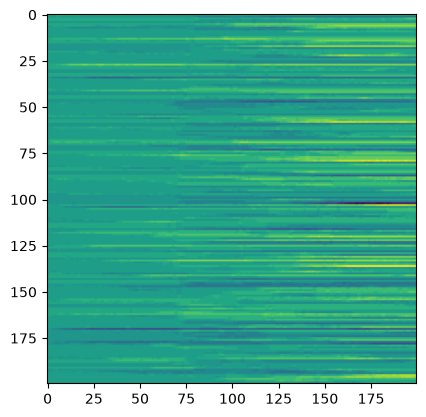

In [106]:
best = [[0 for i in range(len(coeffs))] for j in range(len(coeffs[0]))]
for i in range(len(coeffs)):
    for j in range(len(coeffs[0])):
        best[i][j] = coeffs[i][j][0]

plt.imshow(np.unwrap(np.angle(best),axis=-1))

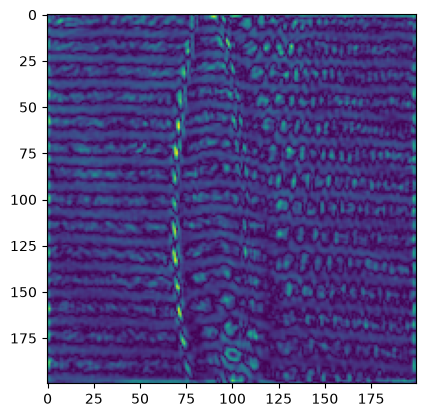

In [104]:
plt.imshow(np.abs(best))